<a href="https://colab.research.google.com/github/Ikelia/klab-ai-kelia/blob/SetupandData/00_setup_and_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Waste Sorter · 00 Setup and data

**Week 1.** Run this notebook once per team, before any other notebook. It:

1. saves the shared helper file `ws_utils.py` to your Drive folder,
2. downloads TrashNet, removes duplicate images and makes the **fixed split** (70 / 15 / 15, seed 42),
3. lets you explore the data.

Runtime → Change runtime type → **T4 GPU** is not needed here, but it is for every later notebook.

In [1]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)

ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
os.makedirs(ROOT, exist_ok=True)
TEAM = "team_name_here"   # <- change to your team name; it is written into results.csv
print("Project folder:", ROOT)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/waste_sorter


## 1. Save the shared helpers
Every notebook imports `ws_utils.py` from your Drive folder. Read it once: it holds the data loaders,
the training loop, the metrics and `log_result`, which writes to `results.csv`. **Do not change it.**

In [2]:
%%writefile {ROOT}/ws_utils.py
"""Shared helpers for the Smart Waste Sorter project (Computer Vision course).

Every notebook imports this file. Do not change the split or the metrics:
all teams must measure the same things the same way.
"""
import os, sys, csv, time, random, shutil, glob
from datetime import datetime

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
RECYCLABLE = ["cardboard", "glass", "metal", "paper", "plastic"]
SEED = 42
SMOKE = os.environ.get("SMOKE_TEST") == "1"   # instructors only: tiny fake run on CPU
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

ROOT = None        # Drive folder: MyDrive/waste_sorter
LOCAL = None       # fast local copy of the data inside the Colab VM
TEAM = "unnamed"


def setup(team, root=None):
    """Set paths, copy data to the local disk, fix seeds. Call once at the top of every notebook."""
    global ROOT, LOCAL, TEAM
    TEAM = team
    ROOT = root or os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if "google.colab" in sys.modules else "./waste_sorter")
    LOCAL = os.environ.get("WS_LOCAL") or ("/content/ws_data" if "google.colab" in sys.modules else os.path.join(ROOT, "_local"))
    for sub in ["data", "local_test", "checkpoints", "figures"]:
        os.makedirs(os.path.join(ROOT, sub), exist_ok=True)
    src = os.path.join(ROOT, "data")
    if os.path.exists(os.path.join(src, "split.csv")) and not os.path.exists(os.path.join(LOCAL, "split.csv")):
        print("Copying data from Drive to the local disk (once per session)...")
        shutil.copytree(src, LOCAL, dirs_exist_ok=True)
    seed_everything()
    print(f"Team: {TEAM} | root: {ROOT} | device: {device()} | smoke test: {SMOKE}")


def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def epochs(n):
    """Number of epochs to use: n normally, 1 in a smoke test."""
    return 1 if SMOKE else n


# ---------------------------------------------------------------- data
def load_split():
    """The fixed split every team uses: columns path, label, label_id, split."""
    df = pd.read_csv(os.path.join(LOCAL, "split.csv"))
    df["path"] = df["path"].apply(lambda p: os.path.join(LOCAL, p))
    return df


class WasteDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = list(paths), list(labels), transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]


class TensorImages(Dataset):
    """Wraps already-made image tensors (e.g. GAN samples) so they can join a training set."""
    def __init__(self, images, label_id, transform):
        self.images, self.label_id, self.transform = images, label_id, transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        x = self.images[i]                      # tensor in [-1, 1], shape (3, H, W)
        img = Image.fromarray(((x.clamp(-1, 1) + 1) * 127.5).byte().permute(1, 2, 0).cpu().numpy())
        return self.transform(img), self.label_id


def transforms_for(img_size, augment=False, normalize="imagenet"):
    from torchvision import transforms as T
    # "imagenet" for pretrained classifiers, "tanh" for [-1, 1] (GAN), None for [0, 1] (VAE)
    norm = {"imagenet": [T.Normalize(IMAGENET_MEAN, IMAGENET_STD)], "tanh": [T.Normalize((0.5,) * 3, (0.5,) * 3)], None: []}[normalize]
    if augment:
        return T.Compose([T.RandomResizedCrop(img_size, scale=(0.7, 1.0)), T.RandomHorizontalFlip(),
                          T.RandomRotation(15), T.ColorJitter(0.2, 0.2, 0.2), T.ToTensor(), *norm])
    return T.Compose([T.Resize((img_size, img_size)), T.ToTensor(), *norm])


def make_loaders(img_size, batch_size=32, train_fraction=1.0, augment=False, normalize="imagenet",
                 classes=None, extra_train=None):
    """Train/val/test DataLoaders on the fixed split.

    train_fraction: use only this share of the training split (stratified, same seed for everyone).
    classes:        keep only these class names (e.g. RECYCLABLE for the VAE).
    extra_train:    an extra Dataset added to training (e.g. GAN images).
    """
    df = load_split()
    if classes is not None:
        df = df[df["label"].isin(classes)]
    tr = df[df.split == "train"]
    if train_fraction < 1.0:
        tr = tr.groupby("label", group_keys=False).apply(
            lambda g: g.sample(max(1, int(round(len(g) * train_fraction))), random_state=SEED))
    t_train = transforms_for(img_size, augment, normalize)
    t_eval = transforms_for(img_size, False, normalize)
    train_ds = WasteDataset(tr.path, tr.label_id, t_train)
    if extra_train is not None:
        train_ds = torch.utils.data.ConcatDataset([train_ds, extra_train])
    va, te = df[df.split == "val"], df[df.split == "test"]
    nw = 0 if SMOKE else 2
    return (DataLoader(train_ds, batch_size, shuffle=True, num_workers=nw, drop_last=len(train_ds) > batch_size),
            DataLoader(WasteDataset(va.path, va.label_id, t_eval), batch_size, num_workers=nw),
            DataLoader(WasteDataset(te.path, te.label_id, t_eval), batch_size, num_workers=nw))


def local_test_loader(img_size, batch_size=32, normalize="imagenet"):
    """Your 60 phone photos in ROOT/local_test/<class>/*.jpg. Returns None if the folder is empty."""
    paths, labels = [], []
    for i, c in enumerate(CLASSES):
        for p in sorted(glob.glob(os.path.join(ROOT, "local_test", c, "*"))):
            if p.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
                paths.append(p); labels.append(i)
    if not paths:
        print("No local photos yet: add them to", os.path.join(ROOT, "local_test", "<class>"))
        return None
    return DataLoader(WasteDataset(paths, labels, transforms_for(img_size, False, normalize)), batch_size)


# ---------------------------------------------------------------- training + metrics
def train_classifier(model, train_loader, val_loader, n_epochs, lr=1e-3, weight_decay=1e-4):
    """A standard training loop with cross-entropy and AdamW. Keeps the weights with the best val macro-F1."""
    dev = device(); model.to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, n_epochs))
    loss_fn = torch.nn.CrossEntropyLoss()
    best, best_state, t0 = -1, None, time.time()
    for ep in range(n_epochs):
        model.train(); total = 0
        for x, y in train_loader:
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); opt.step()
            total += loss.item() * len(y)
        sched.step()
        val = evaluate(model, val_loader)
        print(f"epoch {ep + 1}/{n_epochs}  train loss {total / len(train_loader.dataset):.3f}  "
              f"val acc {val['accuracy']:.3f}  val macro-F1 {val['macro_f1']:.3f}")
        if val["macro_f1"] > best:
            best, best_state = val["macro_f1"], {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return (time.time() - t0) / 60


@torch.no_grad()
def predict(model, loader):
    dev = device(); model.to(dev).eval()
    ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(dev)).argmax(1).cpu()); ys.append(torch.as_tensor(y))
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()


def metrics(y_true, y_pred):
    trash = CLASSES.index("trash")
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", labels=list(range(len(CLASSES))), zero_division=0),
            "trash_f1": f1_score(y_true, y_pred, labels=[trash], average="macro", zero_division=0),
            "y_true": y_true, "y_pred": y_pred}


def evaluate(model, loader):
    return metrics(*predict(model, loader))


def plot_confusion(m, title=""):
    import matplotlib.pyplot as plt
    cm = confusion_matrix(m["y_true"], m["y_pred"], labels=list(range(len(CLASSES))))
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right"); ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    plt.tight_layout(); plt.show()


def count_params(model):
    return sum(p.numel() for p in model.parameters()) / 1e6


def save_figure(fig, name):
    fig.savefig(os.path.join(ROOT, "figures", name), dpi=150, bbox_inches="tight")


# ---------------------------------------------------------------- results.csv
FIELDS = ["timestamp", "team", "week", "method", "train_fraction", "test_accuracy", "test_macro_f1",
          "trash_f1", "local_accuracy", "params_millions", "train_minutes", "notes"]


def log_result(week, method, test=None, local=None, train_fraction=1.0, params_millions=None,
               train_minutes=None, notes="", **extra):
    """Append one experiment to ROOT/results.csv. Extra keyword values go into notes."""
    path = os.path.join(ROOT, "results.csv")
    new = not os.path.exists(path)
    fmt = lambda v: "" if v is None else (f"{v:.4f}" if isinstance(v, float) else v)
    note = "; ".join([notes] + [f"{k}={fmt(v)}" for k, v in extra.items()]).strip("; ")
    row = {"timestamp": datetime.now().isoformat(timespec="minutes"), "team": TEAM, "week": week, "method": method,
           "train_fraction": train_fraction,
           "test_accuracy": fmt(test["accuracy"]) if test else "", "test_macro_f1": fmt(test["macro_f1"]) if test else "",
           "trash_f1": fmt(test["trash_f1"]) if test else "", "local_accuracy": fmt(local["accuracy"]) if local else "",
           "params_millions": fmt(params_millions), "train_minutes": fmt(train_minutes), "notes": note}
    with open(path, "a", newline="") as f:
        w = csv.DictWriter(f, FIELDS)
        if new:
            w.writeheader()
        w.writerow(row)
    print("Logged:", {k: row[k] for k in ["method", "test_accuracy", "test_macro_f1", "trash_f1", "local_accuracy"]})


# ---------------------------------------------------------------- instructors: offline smoke test only
def tiny_random_clip():
    """A tiny, untrained CLIP + a fake processor, so notebook 05 can be checked without downloads."""
    from transformers import CLIPConfig, CLIPModel
    cfg = CLIPConfig(text_config=dict(hidden_size=32, intermediate_size=37, num_attention_heads=4, num_hidden_layers=2,
                                      vocab_size=50000),
                     vision_config=dict(hidden_size=32, intermediate_size=37, num_attention_heads=4, num_hidden_layers=2,
                                        image_size=32, patch_size=8), projection_dim=16)

    class FakeProcessor:
        def __call__(self, images=None, text=None, return_tensors="pt", padding=True):
            from torchvision import transforms as T
            if images is not None:
                tf = T.Compose([T.Resize((32, 32)), T.ToTensor()])
                return _Batch(pixel_values=torch.stack([tf(i) for i in images]))
            ids = [[hash(w) % 49000 + 1 for w in t.split()][:16] for t in text]
            n = max(len(i) for i in ids)
            return _Batch(input_ids=torch.tensor([i + [0] * (n - len(i)) for i in ids]))

    return CLIPModel(cfg), FakeProcessor()


class _Batch(dict):
    def to(self, dev):
        return _Batch({k: v.to(dev) for k, v in self.items()})


Overwriting /content/drive/MyDrive/waste_sorter/ws_utils.py


In [3]:
sys.path.insert(0, ROOT)
import importlib, ws_utils as ws
importlib.reload(ws)

<module 'ws_utils' from '/content/drive/MyDrive/waste_sorter/ws_utils.py'>

## 2. Download TrashNet and remove duplicates
The Hugging Face copy has about 5,050 rows, while the original release has 2,527 images.
We remove duplicates with a *difference hash*: shrink each image to 17×16 grey pixels and record, for every
pixel, whether it is brighter than its right-hand neighbour. Two images with the same 256-bit hash are
treated as the same photo.

In [5]:
import numpy as np
from PIL import Image, ImageDraw
import os, subprocess, zipfile, glob

def dhash(img, size=16):
    g = np.asarray(img.convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten().tobytes()

def fake_trashnet():
    """Smoke-test stand-in for TrashNet: coloured shapes, with a few exact duplicates."""
    rng = np.random.default_rng(0)
    colours = [(150, 110, 70), (90, 160, 140), (160, 160, 170), (230, 230, 220), (60, 120, 200), (90, 60, 60)]
    items = []
    for c, col in enumerate(colours):
        for i in range(30 if c < 5 else 12):
            img = Image.new("RGB", (512, 384), (245, 245, 245)); d = ImageDraw.Draw(img)
            x, y = rng.integers(40, 300), rng.integers(40, 200)
            d.ellipse([x, y, x + rng.integers(80, 200), y + rng.integers(60, 160)], fill=tuple(int(v) for v in np.clip(np.array(col) + rng.integers(-20, 20, 3), 0, 255)))
            items.append((img, c))
    items += items[:8]
    return items, ws.CLASSES

if ws.SMOKE:
    items, names = fake_trashnet()
else:
    # --- FIX: Download original TrashNet directly from GitHub ---
    print("Downloading original TrashNet dataset from GitHub...")
    zip_path = "/content/trashnet.zip"
    extract_path = "/content/trashnet_data"

    # Download the official dataset zip
    subprocess.run(["wget", "-q", "https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip", "-O", zip_path], check=True)

    # Extract it
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    # Load images manually into the same format the rest of the notebook expects
    names = ws.CLASSES
    items = []
    for i, class_name in enumerate(names):
        class_dir = os.path.join(extract_path, "dataset-resized", class_name)
        for img_path in glob.glob(os.path.join(class_dir, "*.jpg")):
            items.append((Image.open(img_path), i))

    print(f"Loaded {len(items)} original images from GitHub.")

# --- Duplicate removal logic (unchanged) ---
seen, kept, dropped = set(), [], 0
for img, lab in items:
    h = dhash(img)
    if h in seen:
        dropped += 1
        continue
    seen.add(h)
    kept.append((img.convert("RGB"), names[lab]))
print(f"kept {len(kept)} images, removed {dropped} duplicates")
assert [n.lower() for n in names] == ws.CLASSES, names

Loaded 2527 original images from GitHub.
kept 2524 images, removed 3 duplicates


## 3. Make the fixed split and save it
Stratified by class, seed 42. Images are saved at most 320 px on the long side, which is enough for the
224 × 224 models and keeps Drive fast.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.DataFrame({"idx": range(len(kept)), "label": [lab for _, lab in kept]})
train, rest = train_test_split(df, test_size=0.30, stratify=df.label, random_state=ws.SEED)
val, test = train_test_split(rest, test_size=0.50, stratify=rest.label, random_state=ws.SEED)
df.loc[train.index, "split"], df.loc[val.index, "split"], df.loc[test.index, "split"] = "train", "val", "test"

rows = []
for r in df.itertuples():
    rel = f"images/{r.label}/{r.idx:05d}.jpg"
    out = os.path.join(ROOT, "data", rel)
    os.makedirs(os.path.dirname(out), exist_ok=True)
    img = kept[r.idx][0].copy(); img.thumbnail((320, 320))
    img.save(out, quality=92)
    rows.append({"path": rel, "label": r.label, "label_id": ws.CLASSES.index(r.label), "split": r.split})
pd.DataFrame(rows).to_csv(os.path.join(ROOT, "data", "split.csv"), index=False)
for c in ws.CLASSES:
    os.makedirs(os.path.join(ROOT, "local_test", c), exist_ok=True)

ws.setup(TEAM)
split = ws.load_split()
print(pd.crosstab(split.label, split.split, margins=True))

Copying data from Drive to the local disk (once per session)...
Team: team_name_here | root: /content/drive/MyDrive/waste_sorter | device: cuda | smoke test: False
split      test  train  val   All
label                            
cardboard    60    282   61   403
glass        76    350   75   501
metal        61    286   62   409
paper        89    416   89   594
plastic      72    336   72   480
trash        21     96   20   137
All         379   1766  379  2524


## 4. Explore the data
**TODO 1.** Draw a bar chart of the number of training images per class, with the class names on the
x-axis. Which class is smallest, and how many times smaller is it than the largest?

In [8]:
import numpy as np
from PIL import Image, ImageDraw
import os, subprocess, zipfile, glob

def dhash(img, size=16):
    g = np.asarray(img.convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten().tobytes()

def fake_trashnet():
    """Smoke-test stand-in for TrashNet: coloured shapes, with a few exact duplicates."""
    rng = np.random.default_rng(0)
    colours = [(150, 110, 70), (90, 160, 140), (160, 160, 170), (230, 230, 220), (60, 120, 200), (90, 60, 60)]
    items = []
    for c, col in enumerate(colours):
        for i in range(30 if c < 5 else 12):
            img = Image.new("RGB", (512, 384), (245, 245, 245)); d = ImageDraw.Draw(img)
            x, y = rng.integers(40, 300), rng.integers(40, 200)
            d.ellipse([x, y, x + rng.integers(80, 200), y + rng.integers(60, 160)], fill=tuple(int(v) for v in np.clip(np.array(col) + rng.integers(-20, 20, 3), 0, 255)))
            items.append((img, c))
    items += items[:8]
    return items, ws.CLASSES

if ws.SMOKE:
    items, names = fake_trashnet()
else:
    # --- FIX: Download original TrashNet directly from GitHub ---
    print("Downloading original TrashNet dataset from GitHub...")
    zip_path = "/content/trashnet.zip"
    extract_path = "/content/trashnet_data"

    # Download the official dataset zip
    subprocess.run(["wget", "-q", "https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip", "-O", zip_path], check=True)

    # Extract it
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    # Load images manually into the same format the rest of the notebook expects
    names = ws.CLASSES
    items = []
    for i, class_name in enumerate(names):
        class_dir = os.path.join(extract_path, "dataset-resized", class_name)
        for img_path in glob.glob(os.path.join(class_dir, "*.jpg")):
            items.append((Image.open(img_path), i))

    print(f"Loaded {len(items)} original images from GitHub.")

# --- Duplicate removal logic (unchanged) ---
seen, kept, dropped = set(), [], 0
for img, lab in items:
    h = dhash(img)
    if h in seen:
        dropped += 1
        continue
    seen.add(h)
    kept.append((img.convert("RGB"), names[lab]))
print(f"kept {len(kept)} images, removed {dropped} duplicates")
assert [n.lower() for n in names] == ws.CLASSES, names

Loaded 2527 original images from GitHub.
kept 2524 images, removed 3 duplicates


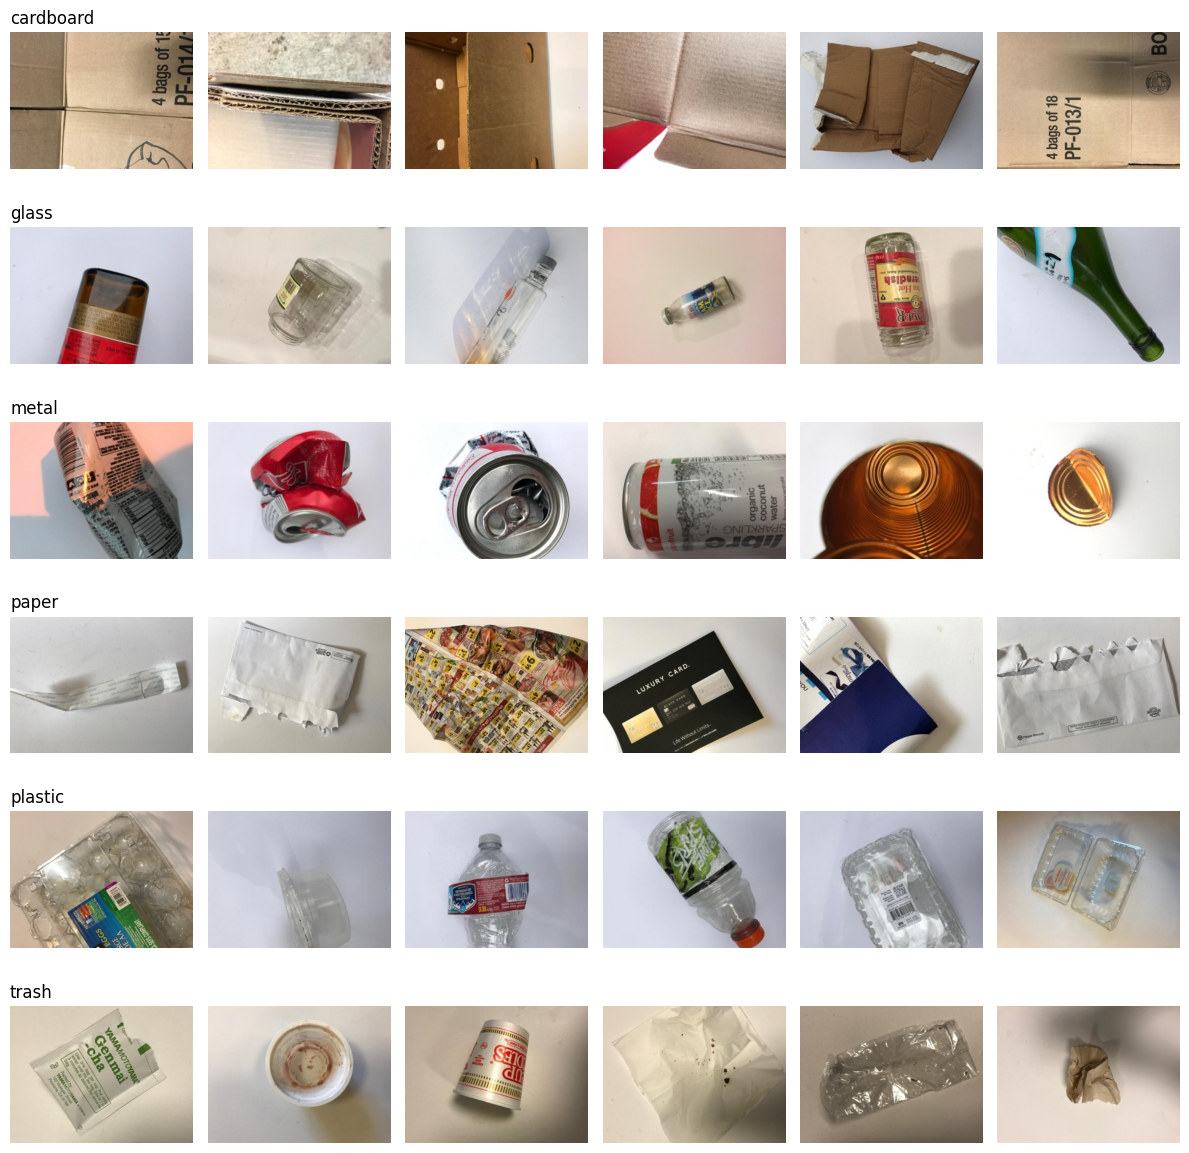

In [9]:
# Six random training images per class
fig, axes = plt.subplots(len(ws.CLASSES), 6, figsize=(12, 12))
for i, c in enumerate(ws.CLASSES):
    sample = split[(split.split == "train") & (split.label == c)].sample(6, random_state=1)
    for j, p in enumerate(sample.path):
        axes[i, j].imshow(Image.open(p)); axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left")
plt.tight_layout(); plt.show()

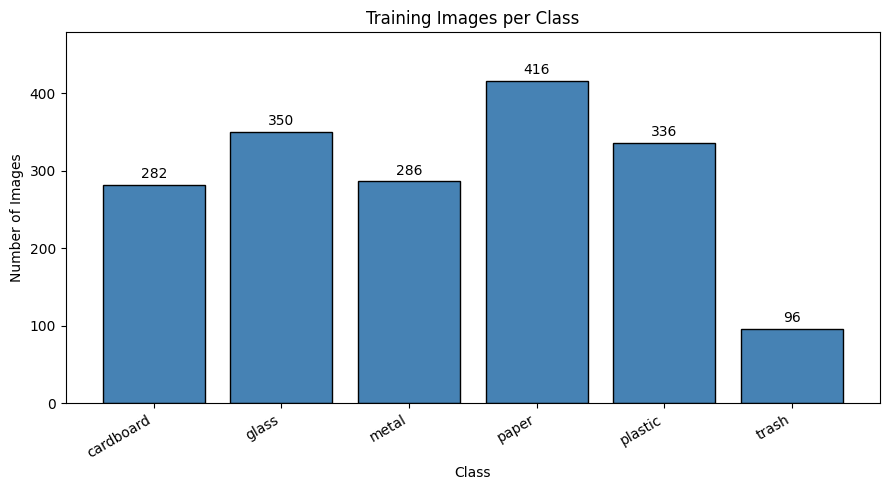

Smallest class : 'trash' with 96 training images
Largest class  : 'paper' with 416 training images
The largest class is 4.33× bigger than the smallest.


In [10]:
import matplotlib.pyplot as plt

# Calculate the number of training images per class
train_counts = split[split.split == "train"].label.value_counts().reindex(ws.CLASSES)

# --- TODO 1: Draw the bar chart ---
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(train_counts.index, train_counts.values, color="steelblue", edgecolor="black")

# Add the numeric count on top of each bar
for bar, count in zip(bars, train_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            str(count), ha="center", va="bottom", fontsize=10)

ax.set_title("Training Images per Class")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Images")
ax.set_ylim(0, train_counts.max() * 1.15)  # headroom for labels
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# --- Answer the question ---
smallest_class = train_counts.idxmin()
smallest_count = train_counts.min()
largest_class = train_counts.idxmax()
largest_count = train_counts.max()
ratio = largest_count / smallest_count

print(f"Smallest class : '{smallest_class}' with {smallest_count} training images")
print(f"Largest class  : '{largest_class}' with {largest_count} training images")
print(f"The largest class is {ratio:.2f}× bigger than the smallest.")

## 5. Your local test set
Photograph **10 items per class** (60 in total) on ordinary backgrounds: desks, floors, bins, outdoors.
Put them in `waste_sorter/local_test/<class>/` in your Drive. Never train on them; they measure how each
approach copes with real-world photos.

**Questions for your week-1 note**
- Look at the image grid. What could a model use to tell the classes apart that has nothing to do with
  the material (background, lighting, object size)?
- How different do you expect your local photos to look from TrashNet?